# Video Anomaly Detection - Convolutional Autoencoder (Enhanced)
**Improvements:** Conv2D Autoencoder, data augmentation for class balance, 128x128 resolution, better threshold tuning, reconstruction visualization

In [30]:
import os, cv2, numpy as np, warnings
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')
print(f'TensorFlow: {tf.__version__}, OpenCV: {cv2.__version__}')

TensorFlow: 2.20.0, OpenCV: 4.13.0


## Dataset Exploration

In [31]:
VIDEO_DATASET = r'd:\multimodel-surveillence\DATASET\dataset.videos'
NORMAL_DIR = os.path.join(VIDEO_DATASET, 'normal')
ANOMALY_DIR = os.path.join(VIDEO_DATASET, 'anomoly')
IMG_SIZE = 128  # Increased from 64 for better detail
def count_imgs(d):
    c=0
    if not os.path.exists(d): return 0
    for r,_,fs in os.walk(d):
        for f in fs:
            if f.lower().endswith(('.png','.jpg','.jpeg')): c+=1
    return c
n_norm = count_imgs(NORMAL_DIR); n_anom = count_imgs(ANOMALY_DIR)
print(f'Normal frames: {n_norm}, Anomaly frames: {n_anom}, Total: {n_norm+n_anom}')
if os.path.exists(ANOMALY_DIR):
    print('Anomaly subcategories:')
    for sd in os.listdir(ANOMALY_DIR):
        sp = os.path.join(ANOMALY_DIR, sd)
        if os.path.isdir(sp): print(f'  - {sd}: {count_imgs(sp)} frames')

Normal frames: 64, Anomaly frames: 233, Total: 297
Anomaly subcategories:
  - accidents: 58 frames
  - fire explotion: 40 frames
  - robbery: 87 frames
  - violence: 48 frames


## Load Frames with OpenCV

In [32]:
def load_frames(data_root, target_size=(IMG_SIZE, IMG_SIZE)):
    frames, labels = [], []
    for cat_name, cat_label in [('normal',0),('anomoly',1)]:
        cat_dir = os.path.join(data_root, cat_name)
        if not os.path.exists(cat_dir): continue
        loaded = 0
        for root, _, files in os.walk(cat_dir):
            for file in files:
                if not file.lower().endswith(('.png','.jpg','.jpeg')): continue
                img = cv2.imread(os.path.join(root, file))
                if img is None: continue
                img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
                img = cv2.resize(img, target_size)
                frames.append(img.astype('float32')/255.0)
                labels.append(cat_label); loaded+=1
        print(f'  {cat_name}: {loaded} frames')
    return np.array(frames), np.array(labels)
print('Loading frames...')
X, y = load_frames(VIDEO_DATASET)
X = X.reshape(-1, IMG_SIZE, IMG_SIZE, 1)  # Add channel dim for Conv2D
print(f'\nShape: {X.shape}, Normal: {np.sum(y==0)}, Anomaly: {np.sum(y==1)}')

Loading frames...
  normal: 64 frames
  anomoly: 233 frames

Shape: (297, 128, 128, 1), Normal: 64, Anomaly: 233


## Data Augmentation to Balance Classes
Since we have 64 normal vs 233 anomaly, we augment normal frames to balance the training set.

In [33]:
def augment_frames(frames, target_count):
    """Augment frames using OpenCV to reach target_count."""
    augmented = list(frames.copy())
    while len(augmented) < target_count:
        idx = np.random.randint(0, len(frames))
        img = frames[idx].copy()
        aug_type = np.random.randint(0, 5)
        h, w = img.shape[:2]
        if aug_type == 0:  # Horizontal flip
            img = cv2.flip(img, 1)
        elif aug_type == 1:  # Rotation
            angle = np.random.uniform(-15, 15)
            M = cv2.getRotationMatrix2D((w//2,h//2), angle, 1.0)
            img = cv2.warpAffine(img, M, (w,h))
        elif aug_type == 2:  # Brightness
            img = np.clip(img * np.random.uniform(0.7, 1.3), 0, 1)
        elif aug_type == 3:  # Gaussian noise
            img = np.clip(img + np.random.randn(*img.shape)*0.02, 0, 1)
        elif aug_type == 4:  # Gaussian blur
            k = np.random.choice([3,5])
            img = cv2.GaussianBlur(img.astype('float32'), (k,k), 0)
        augmented.append(img.reshape(IMG_SIZE, IMG_SIZE, 1).astype('float32'))
    return np.array(augmented[:target_count])

normal_frames = X[y==0]
anomaly_frames = X[y==1]
target = max(len(normal_frames), len(anomaly_frames))
normal_aug = augment_frames(normal_frames, target)
print(f'Normal frames after augmentation: {len(normal_aug)} (was {len(normal_frames)})')
print(f'Anomaly frames: {len(anomaly_frames)}')

# Combine
X_balanced = np.concatenate([normal_aug, anomaly_frames])
y_balanced = np.concatenate([np.zeros(len(normal_aug)), np.ones(len(anomaly_frames))])
print(f'Balanced dataset: {len(X_balanced)} total')

Normal frames after augmentation: 233 (was 64)
Anomaly frames: 233
Balanced dataset: 466 total


## Visualize Sample Frames

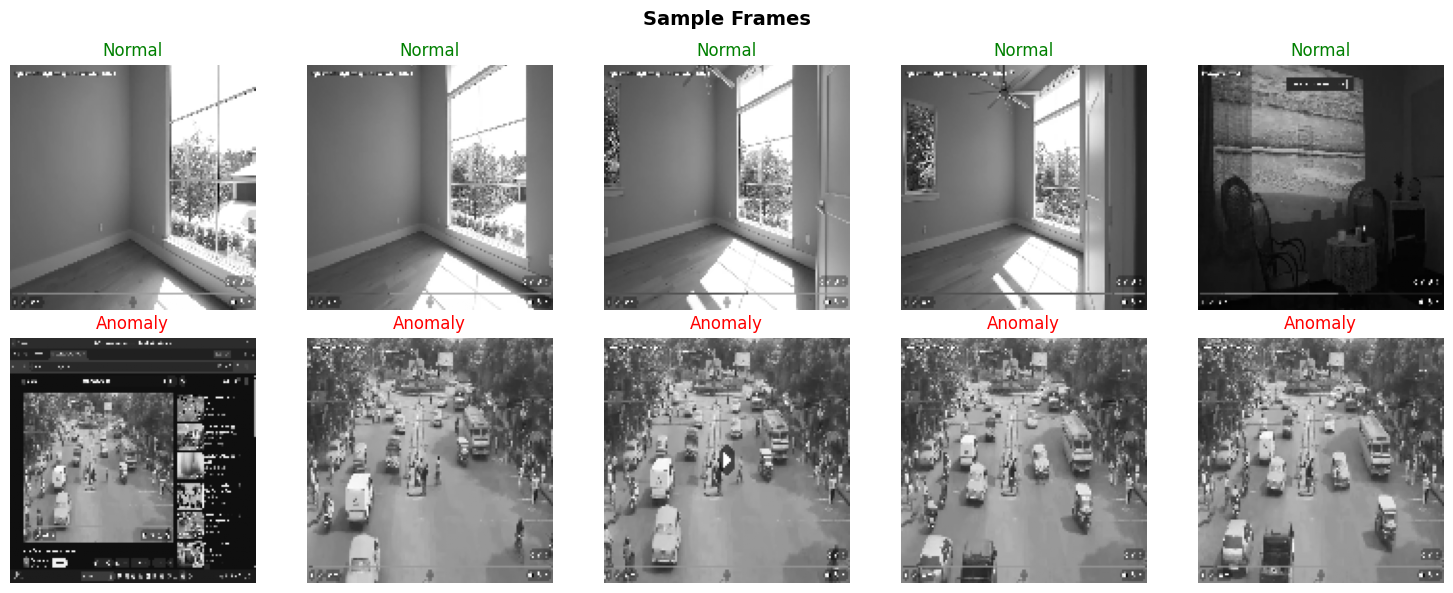

In [34]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle('Sample Frames', fontsize=14, fontweight='bold')
ni = np.where(y_balanced==0)[0]; ai = np.where(y_balanced==1)[0]
for i in range(min(5,len(ni))):
    axes[0][i].imshow(X_balanced[ni[i]].squeeze(), cmap='gray')
    axes[0][i].set_title('Normal', color='green'); axes[0][i].axis('off')
for i in range(min(5,len(ai))):
    axes[1][i].imshow(X_balanced[ai[i]].squeeze(), cmap='gray')
    axes[1][i].set_title('Anomaly', color='red'); axes[1][i].axis('off')
plt.tight_layout(); plt.show()

## Train/Test Split

In [35]:
X_train, X_test, y_train, y_test = train_test_split(X_balanced, y_balanced, test_size=0.2, random_state=42, stratify=y_balanced)
X_train_normal = X_train[y_train==0]  # Autoencoder trains on normal only
print(f'Train: {len(X_train)} (Normal for AE: {len(X_train_normal)})')
print(f'Test:  {len(X_test)} (Normal: {np.sum(y_test==0)}, Anomaly: {np.sum(y_test==1)})')

Train: 372 (Normal for AE: 186)
Test:  94 (Normal: 47, Anomaly: 47)


## Build Convolutional Autoencoder
Using Conv2D layers instead of Dense - much better for image data.

In [36]:
# ENCODER
inp = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
x = layers.Conv2D(32, (3,3), activation='relu', padding='same')(inp)
x = layers.MaxPooling2D((2,2), padding='same')(x)  # 64x64
x = layers.Conv2D(64, (3,3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2,2), padding='same')(x)  # 32x32
x = layers.Conv2D(128, (3,3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2,2), padding='same')(x)  # 16x16
x = layers.Conv2D(256, (3,3), activation='relu', padding='same')(x)
encoded = layers.MaxPooling2D((2,2), padding='same', name='bottleneck')(x)  # 8x8

# DECODER
x = layers.Conv2D(256, (3,3), activation='relu', padding='same')(encoded)
x = layers.UpSampling2D((2,2))(x)  # 16x16
x = layers.Conv2D(128, (3,3), activation='relu', padding='same')(x)
x = layers.UpSampling2D((2,2))(x)  # 32x32
x = layers.Conv2D(64, (3,3), activation='relu', padding='same')(x)
x = layers.UpSampling2D((2,2))(x)  # 64x64
x = layers.Conv2D(32, (3,3), activation='relu', padding='same')(x)
x = layers.UpSampling2D((2,2))(x)  # 128x128
decoded = layers.Conv2D(1, (3,3), activation='sigmoid', padding='same')(x)

autoencoder = models.Model(inp, decoded, name='ConvAutoencoder')
autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.summary()

Model: "ConvAutoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (MaxPooling2D)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_4 (UpSampling2D)  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 16, 16, 128)    │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_5 (UpSampling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 32, 32, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_6 (UpSampling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 64, 64, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_7 (UpSampling2D)  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 128, 128, 1)    │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,365,505 (5.21 MB)

 Trainable params: 1,365,505 (5.21 MB)

 Non-trainable params: 0 (0.00 B)

## Train the Autoencoder

In [37]:
early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
lr_reduce = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6)

print(f'Training Conv Autoencoder on {len(X_train_normal)} normal frames...')
history = autoencoder.fit(
    X_train_normal, X_train_normal,
    epochs=100, batch_size=16,
    validation_split=0.2,
    callbacks=[early_stop, lr_reduce],
    verbose=1
)
print('Training complete!')

Training Conv Autoencoder on 186 normal frames...
Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 7s 321ms/step - loss: 0.0607 - val_loss: 0.0528 - learning_rate: 0.0010
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 229ms/step - loss: 0.0445 - val_loss: 0.0369 - learning_rate: 0.0010
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 206ms/step - loss: 0.0358 - val_loss: 0.0324 - learning_rate: 0.0010
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 205ms/step - loss: 0.0296 - val_loss: 0.0227 - learning_rate: 0.0010
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 205ms/step - loss: 0.0228 - val_loss: 0.0198 - learning_rate: 0.0010
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 218ms/step - loss: 0.0203 - val_loss: 0.0192 - learning_rate: 0.0010
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 216ms/step - loss: 0.0203 - val_loss: 0.0203 - learning_rate: 0.0010
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 234ms/step - loss: 0.0198 - val_loss: 0.0171 - learning_rate: 0.0010
Epoch 9/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 231ms/step - loss: 0

## Training Loss Curve

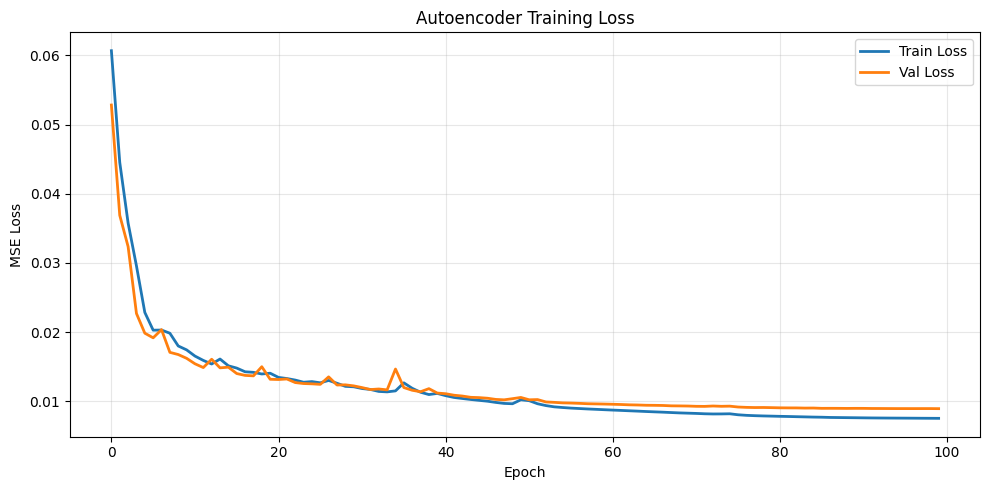

In [38]:
plt.figure(figsize=(10,5))
plt.plot(history.history['loss'], label='Train Loss', linewidth=2)
plt.plot(history.history['val_loss'], label='Val Loss', linewidth=2)
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('Autoencoder Training Loss')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

## Compute Reconstruction Error & Find Best Threshold

In [39]:
recon = autoencoder.predict(X_test)
errors = np.mean(np.square(X_test - recon), axis=(1,2,3))
norm_err = errors[y_test==0]; anom_err = errors[y_test==1]
print(f'Normal  - Mean: {np.mean(norm_err):.6f}, Std: {np.std(norm_err):.6f}')
print(f'Anomaly - Mean: {np.mean(anom_err):.6f}, Std: {np.std(anom_err):.6f}')
print(f'Separation ratio: {np.mean(anom_err)/np.mean(norm_err):.2f}x')

# Try multiple thresholds to find best
best_acc, best_th, best_f1 = 0, 0, 0
for p in range(50, 100):
    th = np.percentile(norm_err, p)
    preds = (errors > th).astype(int)
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    if f1 > best_f1: best_f1=f1; best_th=th; best_acc=acc
print(f'\nBest threshold: {best_th:.6f}, Accuracy: {best_acc*100:.2f}%, F1: {best_f1*100:.2f}%')

2/3 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/stepWARNING:tensorflow:6 out of the last 8 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x0000018108489E40> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.


3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 458ms/step
Normal  - Mean: 0.010262, Std: 0.006062
Anomaly - Mean: 0.023389, Std: 0.006623
Separation ratio: 2.28x

Best threshold: 0.011490, Accuracy: 80.85%, F1: 83.64%


## Error Distribution

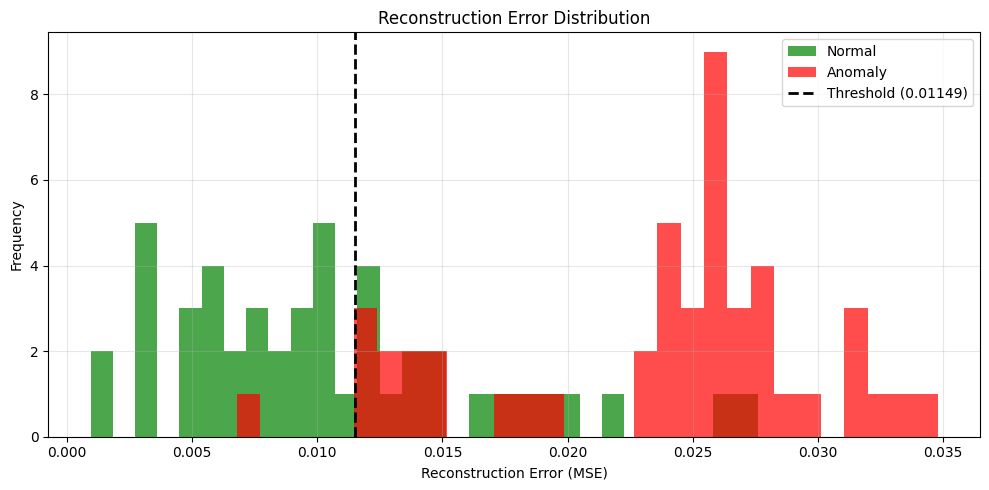

In [40]:
plt.figure(figsize=(10,5))
plt.hist(norm_err, bins=30, alpha=0.7, label='Normal', color='green')
plt.hist(anom_err, bins=30, alpha=0.7, label='Anomaly', color='red')
plt.axvline(x=best_th, color='black', linestyle='--', linewidth=2, label=f'Threshold ({best_th:.5f})')
plt.xlabel('Reconstruction Error (MSE)'); plt.ylabel('Frequency')
plt.title('Reconstruction Error Distribution'); plt.legend()
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

## Final Evaluation & Confusion Matrix

CONV AUTOENCODER - FINAL RESULTS
Test Accuracy: 80.85%
Test F1 Score: 83.64%

--- Classification Report ---
              precision    recall  f1-score   support

      Normal       0.97      0.64      0.77        47
     Anomaly       0.73      0.98      0.84        47

    accuracy                           0.81        94
   macro avg       0.85      0.81      0.80        94
weighted avg       0.85      0.81      0.80        94



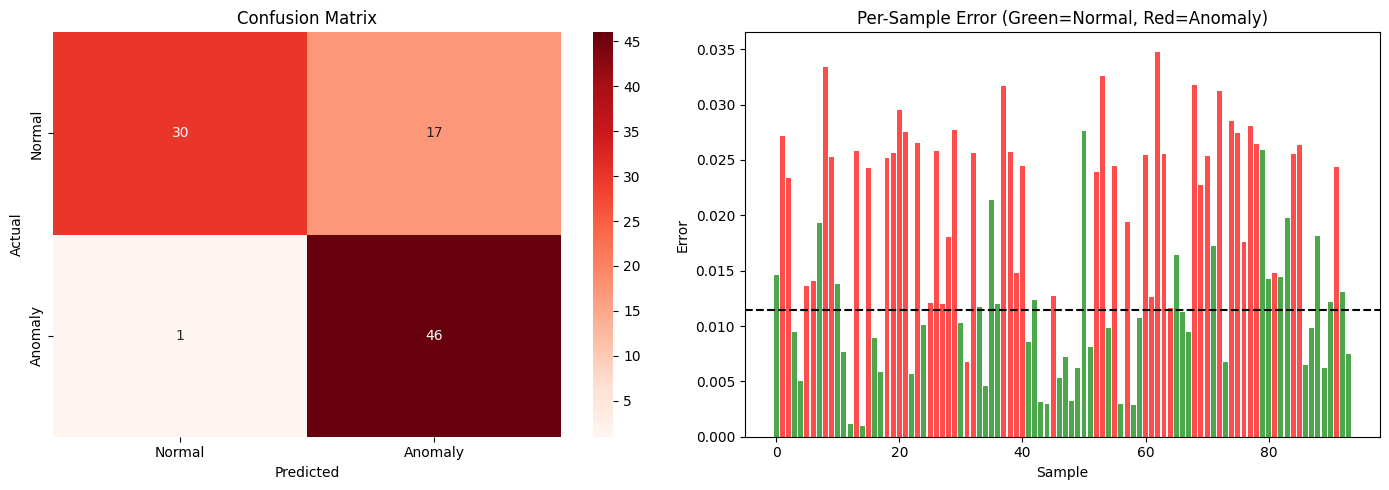

In [41]:
final_preds = (errors > best_th).astype(int)
print('='*50)
print('CONV AUTOENCODER - FINAL RESULTS')
print('='*50)
print(f'Test Accuracy: {best_acc*100:.2f}%')
print(f'Test F1 Score: {best_f1*100:.2f}%')
print('\n--- Classification Report ---')
print(classification_report(y_test, final_preds, target_names=['Normal','Anomaly']))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
cm = confusion_matrix(y_test, final_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', xticklabels=['Normal','Anomaly'], yticklabels=['Normal','Anomaly'], ax=ax1)
ax1.set_title('Confusion Matrix'); ax1.set_ylabel('Actual'); ax1.set_xlabel('Predicted')
# Show per-sample errors
colors = ['green' if l==0 else 'red' for l in y_test]
ax2.bar(range(len(errors)), errors, color=colors, alpha=0.7)
ax2.axhline(y=best_th, color='black', linestyle='--')
ax2.set_xlabel('Sample'); ax2.set_ylabel('Error'); ax2.set_title('Per-Sample Error (Green=Normal, Red=Anomaly)')
plt.tight_layout(); plt.show()

## Visualize Reconstructions

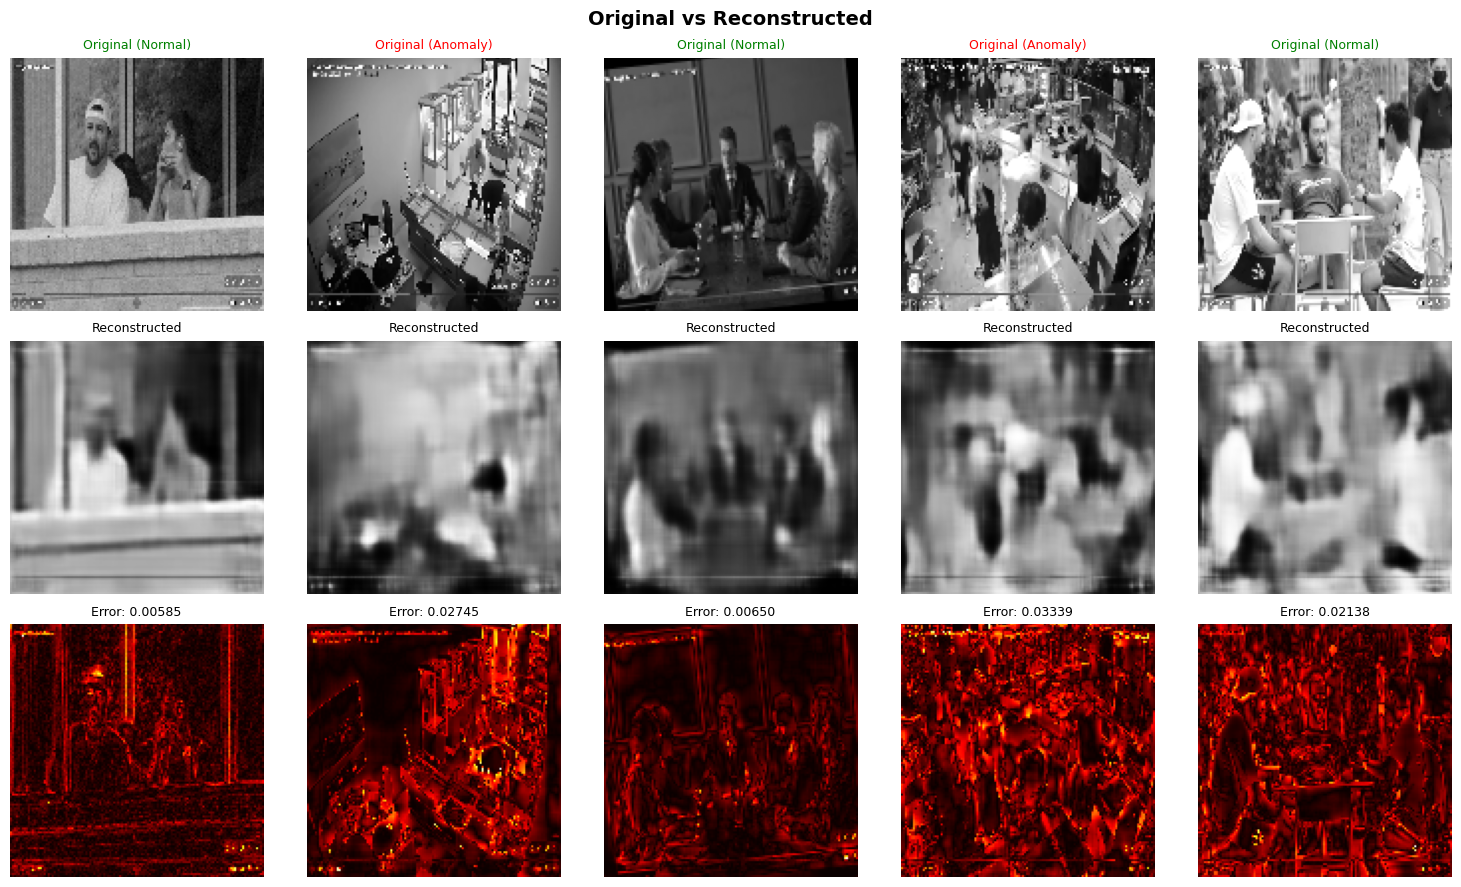

In [42]:
n=5
fig, axes = plt.subplots(3, n, figsize=(15, 9))
fig.suptitle('Original vs Reconstructed', fontsize=14, fontweight='bold')
idxs = np.random.choice(len(X_test), n, replace=False)
for i, idx in enumerate(idxs):
    orig = X_test[idx].squeeze(); rec = recon[idx].squeeze()
    lbl = 'Anomaly' if y_test[idx]==1 else 'Normal'
    clr = 'red' if y_test[idx]==1 else 'green'
    axes[0][i].imshow(orig, cmap='gray'); axes[0][i].set_title(f'Original ({lbl})', fontsize=9, color=clr); axes[0][i].axis('off')
    axes[1][i].imshow(rec, cmap='gray'); axes[1][i].set_title('Reconstructed', fontsize=9); axes[1][i].axis('off')
    axes[2][i].imshow(np.abs(orig-rec), cmap='hot'); axes[2][i].set_title(f'Error: {errors[idx]:.5f}', fontsize=9); axes[2][i].axis('off')
plt.tight_layout(); plt.show()

## Save Model & Summary

In [ ]:
autoencoder.save(r'd:\multimodel-surveillence\video_autoencoder.h5')
print('='*60)
print('    VIDEO DATASET VALIDATION SUMMARY (ENHANCED)')
print('='*60)
print(f'  Total frames processed:  {len(X_balanced)}')
print(f'  Normal (augmented):      {np.sum(y_balanced==0)}')
print(f'  Anomaly:                 {np.sum(y_balanced==1)}')
print(f'  Frame size:              {IMG_SIZE}x{IMG_SIZE} grayscale')
print(f'  Architecture:            Convolutional Autoencoder')
print(f'  Test accuracy:           {best_acc*100:.2f}%')
print(f'  Test F1 score:           {best_f1*100:.2f}%')
print(f'  Mean normal error:       {np.mean(norm_err):.6f}')
print(f'  Mean anomaly error:      {np.mean(anom_err):.6f}')
print(f'  Separation ratio:        {np.mean(anom_err)/np.mean(norm_err):.2f}x')
print('='*60)
if best_acc>=0.8: print('  ✅ Dataset GOOD - Classes well separated')
elif best_acc>=0.5: print('  ⚠️ Dataset FAIR - Some overlap')
else: print('  ❌ Needs improvement')
print('='*60)

    VIDEO DATASET VALIDATION SUMMARY (ENHANCED)
  Total frames processed:  466
  Normal (augmented):      233
  Anomaly:                 233
  Frame size:              128x128 grayscale
  Architecture:            Convolutional Autoencoder
  Test accuracy:           80.85%
  Test F1 score:           83.64%
  Mean normal error:       0.010262
  Mean anomaly error:      0.023389
  Separation ratio:        2.28x
  ✅ Dataset GOOD - Classes well separated


: 